# VRDet: Stage 04a: Hidden Markov Models

The HMM is the backbone of the project. It defines the regimes, and its real-time (filtered) output is both
an input to every classifier and the benchmark they must beat. This notebook covers all the HMM models:

1. what the HMM observes
2. how many states (2–5) and why three
3. the production model: parameters, transitions, durations
4. three ways to decode it: **filtered** (real time), **smoothed**, **Viterbi + minimum duration** (the labels)
5. the sticky prior and minimum-duration smoothing
6. stability of the labels across training windows
7. the HMM filter as a real-time classifier, with argmax and with a tuned threshold
8. per-stock HMMs from the Stock Lab

The labeler is fitted on 2015–2021 only; 2022 onwards is the test period of every classifier.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = REPO / 'data' / 'processed'      # raw data: <repo>/data/raw (or set VRDET_DATA)
FIG = OUT / 'figures'

sys.path.insert(0, str(REPO / 'src'))
for m in [m for m in sys.modules if m == 'vrdet' or m.startswith('vrdet.')]:
    del sys.modules[m]  # forget any previously imported (stale) vrdet
FIG.mkdir(parents=True, exist_ok=True)
print('repo:', REPO)

repo: C:\dev\vrdet


In [2]:
import json
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

logging.getLogger('hmmlearn').setLevel(logging.ERROR)   # "not converging" notes from EM restarts

from vrdet.data import load_raw
from vrdet.evaluate import regime_metrics
from vrdet.labels import STATE_NAMES, HMMLabeler, event_report, min_duration, regime_episodes
from vrdet.live import MODEL_DIR, base_frame, classify

pd.set_option('display.width', 200)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True, 'font.size': 9.5})
REGIME_COLORS = ['#2e9e5b', '#d9a400', '#d93636']      # Quiet, Normal, Chaotic (same as the dashboard)
HIGHLIGHT = {'production': '#2a78d6', 'benchmark': '#eb6834'}   # categorical slots 1-2
GREY = '#9aa3ad'

TRAIN_END, TEST_START = '2021-12-31', '2022-01-01'

raw = load_raw()
f = base_frame(raw)                      # validated causal features (Stage 02)
hmm = HMMLabeler.from_json((MODEL_DIR / 'hmm_labeler.json').read_text())   # the production labeler
print(f'{len(f):,} bars, {f.index[0]:%Y-%m-%d} -> {f.index[-1]:%Y-%m-%d}')

72,634 bars, 2015-01-01 -> 2026-10-29


## 1. What the HMM observes

Two numbers per 15-minute bar, both divided by the time-of-day profile (the open and close are always more
volatile than lunchtime):

* `z`: the deseasonalised return (direction and size of the move)
* `log range_ds`: log of the deseasonalised high–low range (how much the price travelled within the bar)

Both are standardised on the training span. The range is logged because it is strictly positive and right-skewed;
on the log scale its distribution is close to Gaussian, which the emission model assumes.

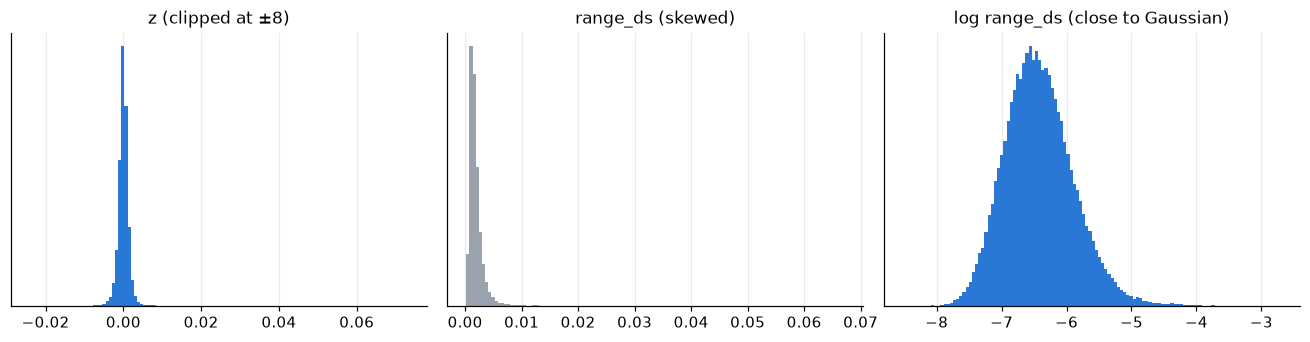

             count   mean    std    min    25%    50%    75%    max
z          72051.0 -0.000  0.001 -0.024 -0.001  0.000  0.001  0.073
log_range  72051.0 -6.421  0.532 -8.526 -6.790 -6.456 -6.095 -2.701


In [3]:
obs = HMMLabeler._raw_obs(f)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(obs['z'].clip(-8, 8), bins=120, color='#2a78d6')
axes[0].set_title('z (clipped at ±8)')
axes[1].hist(np.exp(obs['log_range']).clip(upper=5), bins=120, color=GREY)
axes[1].set_title('range_ds (skewed)')
axes[2].hist(obs['log_range'], bins=120, color='#2a78d6')
axes[2].set_title('log range_ds (close to Gaussian)')
for ax in axes:
    ax.set_yticks([])
fig.tight_layout(); plt.show()
print(obs.describe().T.round(3))

## 2. How many states?

Fit 2–5 state Gaussian HMMs (diagonal covariance, sticky prior, best of 4 starts) on 2015–2021 and compare:
training BIC, the log-likelihood per bar on unseen 2022–2026 data, and how rare and persistent the most
volatile state is.

In [4]:
idx, X_all = hmm.observations(f)
rows, fits = [], {}
for k in range(2, 6):
    lab = HMMLabeler(n_states=k).fit(f, end=TRAIN_END)
    fits[k] = lab
    i, Xk = lab.observations(f)
    train, test = i <= pd.Timestamp(TRAIN_END + ' 23:59', tz=i.tz), i >= pd.Timestamp(TEST_START, tz=i.tz)
    n, d = train.sum(), Xk.shape[1]
    p = (k - 1) + k * (k - 1) + 2 * k * d
    labels_k = lab.hindsight(f)
    top = labels_k == k - 1
    rows.append({'states': k, 'params': p, 'train_loglik': lab.loglik_, 'BIC': -2 * lab.loglik_ + p * np.log(n),
                 'test_loglik_per_bar': lab._hmmlearn_model().score(Xk[test]) / test.sum(),
                 'top_state_share': top.mean(), 'top_state_episodes': len(regime_episodes(labels_k, state=k - 1)),
                 'top_state_mean_bars': (1 / (1 - np.diag(lab.transmat_)))[-1]})
states = pd.DataFrame(rows).set_index('states')
states.round(3)

,params,train_loglik,BIC,test_loglik_per_bar,top_state_share,top_state_episodes,top_state_mean_bars
states,,,,,,,
2,11,-99739.326,199595.863,-2.218,0.276,967,13.959
3,20,-93590.251,187393.613,-2.106,0.074,342,25.521
4,31,-91357.888,183046.096,-2.069,0.012,44,128.259
5,44,-90614.122,181697.087,-2.060,0.006,12,479.009


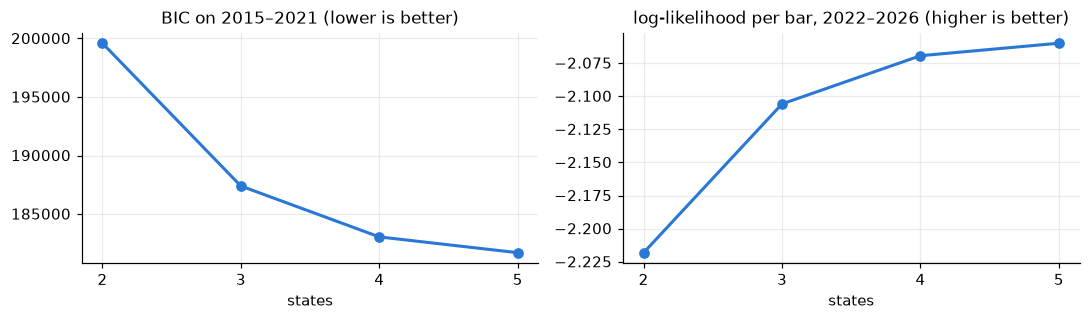

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(states.index, states['BIC'], 'o-', color='#2a78d6', lw=2, ms=6)
axes[0].set_title('BIC on 2015–2021 (lower is better)')
axes[1].plot(states.index, states['test_loglik_per_bar'], 'o-', color='#2a78d6', lw=2, ms=6)
axes[1].set_title('log-likelihood per bar, 2022–2026 (higher is better)')
for ax in axes:
    ax.set_xticks(states.index); ax.set_xlabel('states')
fig.tight_layout(); fig.savefig(FIG / 'hmm_states.png', dpi=130); plt.show()

## 3. The production model (3 states)

States are ordered by mean log range, so 0 = Quiet, 1 = Normal, 2 = Chaotic. `z_sd` is the typical size of a
deseasonalised move in each regime. `range_ds_typical` is the typical range relative to the time-of-day norm.
Expected duration = 1 / (1 − P(stay)).

In [6]:
display(hmm.summary().style.format({'z_sd': '{:.3%}', 'range_ds_typical': '{:.3%}', 'expected_duration_bars': '{:.1f}'}))
trans = pd.DataFrame(hmm.transmat_, index=STATE_NAMES, columns=STATE_NAMES)
trans.round(4)

,z_sd,range_ds_typical,expected_duration_bars
Quiet,0.066%,0.115%,20.1
Normal,0.134%,0.206%,15.2
Chaotic,0.384%,0.423%,25.5


,Quiet,Normal,Chaotic
Quiet,0.9502,0.0465,0.0033
Normal,0.0504,0.9343,0.0153
Chaotic,0.0004,0.0388,0.9608


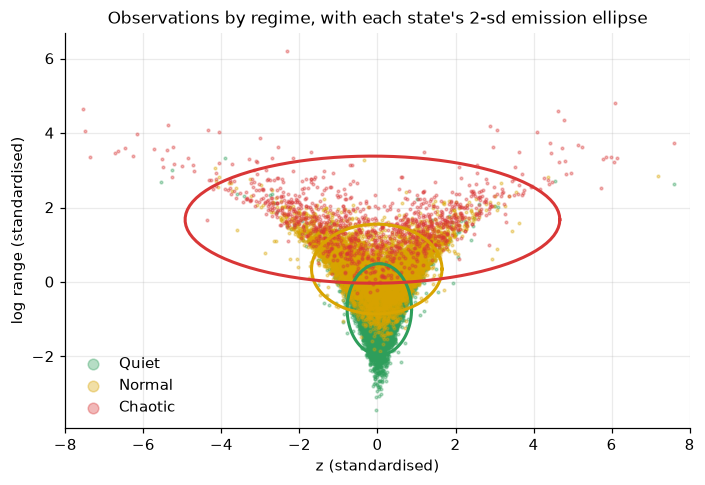

In [7]:
labels = hmm.hindsight(f)
sample = np.random.default_rng(0).choice(len(X_all), 15000, replace=False)
lab_s = labels.reindex(idx).to_numpy()[sample]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k in range(3):
    m = lab_s == k
    ax.scatter(X_all[sample][m, 0], X_all[sample][m, 1], s=3, alpha=0.35, color=REGIME_COLORS[k], label=STATE_NAMES[k])
    mu, sd = hmm.means_[k], np.sqrt(hmm.vars_[k])
    t = np.linspace(0, 2 * np.pi, 100)
    ax.plot(mu[0] + 2 * sd[0] * np.cos(t), mu[1] + 2 * sd[1] * np.sin(t), color=REGIME_COLORS[k], lw=2)
ax.set_xlim(-8, 8)
ax.set_xlabel('z (standardised)'); ax.set_ylabel('log range (standardised)')
ax.set_title('Observations by regime, with each state\'s 2-sd emission ellipse')
ax.legend(frameon=False, markerscale=4)
fig.tight_layout(); fig.savefig(FIG / 'hmm_emissions.png', dpi=130); plt.show()

## 4. Three decodings

* **Filtered** P(state_t | x_1..x_t): forward algorithm only, available in real time (`labels.forward_filter`).
  This is the HMM filter benchmark, and its probabilities are classifier inputs.
* **Smoothed** P(state_t | x_1..x_T): forward–backward, uses future bars.
* **Viterbi + minimum duration**: the single most likely path, then runs shorter than 4 bars merged into their
  predecessor. These are the hindsight **labels** every model is trained to predict.

In [8]:
filt = hmm.filtered_proba(f)
smooth = hmm.smoothed_proba(f)
agree = pd.DataFrame({
    'filtered argmax': (filt.to_numpy().argmax(1) == labels.reindex(filt.index).to_numpy()).mean(),
    'smoothed argmax': (smooth.to_numpy().argmax(1) == labels.reindex(smooth.index).to_numpy()).mean(),
}, index=['agreement with the labels']).round(3)
agree

,filtered argmax,smoothed argmax
agreement with the labels,0.85,0.952


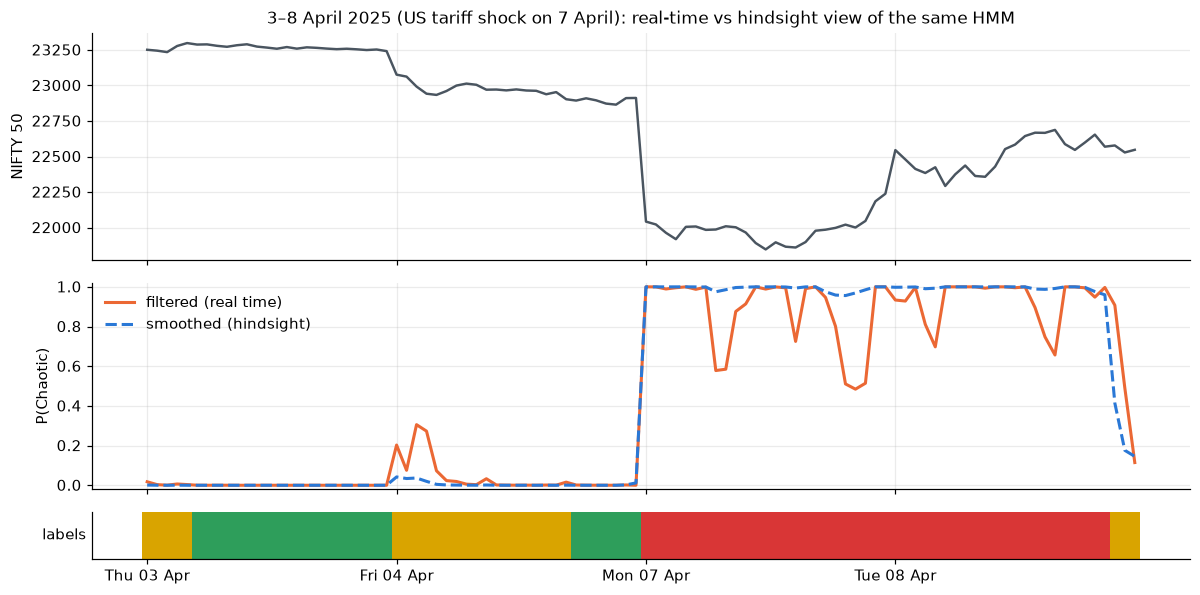

In [9]:
def regime_strip(ax, lab):
    for t, r in enumerate(lab.to_numpy()):
        ax.axvspan(t - 0.5, t + 0.5, color=REGIME_COLORS[int(r)], lw=0)
    ax.set_yticks([]); ax.grid(False)


win = slice('2025-04-03', '2025-04-08')
w = filt.loc[win].index
close = raw['NIFTY_15m']['close'].reindex(w)
fig, axes = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 2, 0.45]})
x = np.arange(len(w))
axes[0].plot(x, close.to_numpy(), color='#4a5560', lw=1.6)
axes[0].set_ylabel('NIFTY 50')
axes[1].plot(x, filt.loc[w, 'Chaotic'], color=HIGHLIGHT['benchmark'], lw=2, label='filtered (real time)')
axes[1].plot(x, smooth.loc[w, 'Chaotic'], color='#2a78d6', lw=2, ls='--', label='smoothed (hindsight)')
axes[1].set_ylabel('P(Chaotic)'); axes[1].set_ylim(-0.02, 1.02); axes[1].legend(frameon=False, loc='upper left')
regime_strip(axes[2], labels.reindex(w)); axes[2].set_ylabel('labels', rotation=0, ha='right', va='center')
starts = [i for i in range(len(w)) if i == 0 or w[i].date() != w[i - 1].date()]
axes[2].set_xticks(starts, [w[i].strftime('%a %d %b') for i in starts])
axes[0].set_title('3–8 April 2025 (US tariff shock on 7 April): real-time vs hindsight view of the same HMM')
fig.tight_layout(); fig.savefig(FIG / 'hmm_decodings.png', dpi=130); plt.show()

## 5. Sticky prior and minimum duration

Without help, an HMM on 15-minute bars flickers between states. Two devices make regimes persistent:

* a **sticky Dirichlet prior** on the transition matrix (pseudo-counts on staying, as a fraction of the training
  length), which shapes the model itself
* **minimum-duration smoothing** of the Viterbi path (runs shorter than k bars merged), which only touches the labels

The production choice is sticky = 0.2, k = 4 (one hour).

In [10]:
def label_stats(lab):
    switches = (lab.diff().fillna(0) != 0).groupby(lab.index.date).sum().mean()
    ep = regime_episodes(lab)
    ev = event_report(lab)
    return {'chaotic_share': (lab == 2).mean(), 'chaotic_episodes': len(ep),
            'median_episode_bars': ep['n_bars'].median(),
            'switches_per_session': switches, 'shock_days_chaotic': ev['Chaotic'].mean()}


rows = []
for sticky in (0.0, 0.05, 0.2, 0.5):
    lab = hmm if sticky == 0.2 else HMMLabeler(sticky=sticky).fit(f, end=TRAIN_END)
    rows.append({'sticky': sticky, 'min_bars': 4, **label_stats(lab.hindsight(f))})
viterbi = pd.Series(hmm._hmmlearn_model().predict(X_all), index=idx)
for k in (1, 2, 8):
    rows.append({'sticky': 0.2, 'min_bars': k, **label_stats(min_duration(viterbi, k))})
pd.DataFrame(rows).set_index(['sticky', 'min_bars']).round(3)

chaotic_share  chaotic_episodes  median_episode_bars  switches_per_session  shock_days_chaotic
sticky min_bars                                                                                                
0.00   4                 0.070               405                  7.0                 1.117               0.908
0.05   4                 0.079               440                  8.0                 1.144               0.908
0.20   4                 0.074               342                  8.5                 0.954               0.892
0.50   4                 0.069               282                  9.0                 0.735               0.892
0.20   1                 0.080               580                  4.0                 1.481               0.892
       2                 0.079               498                  6.0                 1.340               0.892
       8                 0.065               180                 14.5                 0.496               0.868

## 6. Are the labels stable?

If the regimes were an artefact of one training window, refitting on another window would relabel the test
period. Compare the 2022–2026 labels from labelers trained on different spans (Cohen's κ against production).

In [11]:
test_idx = labels.index[labels.index >= pd.Timestamp(TEST_START, tz=labels.index.tz)]
rows = []
for start, end in (('2015-01-01', '2019-12-31'), ('2015-01-01', '2021-12-31'), ('2017-01-01', '2021-12-31'),
                   ('2018-01-01', '2023-12-31')):
    lab = hmm if (start, end) == ('2015-01-01', '2021-12-31') else HMMLabeler().fit(f, start=start, end=end)
    l2 = lab.hindsight(f).reindex(test_idx)
    rows.append({'trained on': f'{start[:4]}-{end[:4]}', 'kappa_vs_production': cohen_kappa_score(labels.reindex(test_idx), l2),
                 'agreement': (l2 == labels.reindex(test_idx)).mean(), 'chaotic_share_2022+': (l2 == 2).mean()})
pd.DataFrame(rows).set_index('trained on').round(3)

,kappa_vs_production,agreement,chaotic_share_2022+
trained on,,,
2015-2019,0.638,0.787,0.146
2015-2021,1.000,1.000,0.052
2017-2021,0.958,0.977,0.046
2018-2023,0.973,0.986,0.048


### Sanity check: known market shocks

Share of bars labelled Chaotic on sessions that any market participant would call chaotic.

In [12]:
event_report(labels)

,event,Quiet,Normal,Chaotic
date,,,,
2015-08-24,"China devaluation crash (""Black Monday"")",0.0,0.16,0.84
2016-06-24,Brexit referendum result,0.0,0.40,0.60
2016-11-09,Demonetisation + US election result,0.0,0.00,1.00
2018-09-21,IL&FS / DHFL intraday crash,0.0,0.52,0.48
2020-03-12,COVID: WHO pandemic declaration sell-off,0.0,0.00,1.00
2020-03-23,"COVID: lower circuit, lockdown",0.0,0.00,1.00
2021-02-01,Union Budget rally,0.0,0.00,1.00
2022-02-24,Russia invades Ukraine,0.0,0.00,1.00
2024-06-04,General election results,0.0,0.00,1.00


## 7. The HMM filter as a real-time classifier

What can the HMM alone do live? Its filtered probabilities are scored against the labels on 2022–2026, the same
test period as the classifier walk-forward. Two decision rules:

* **argmax** (as on the dashboard and in the leaderboard)
* **tuned τ**: Chaotic when filtered P(Chaotic) ≥ τ, with τ tuned on 2021 exactly as for the classifiers. This
  gives the benchmark the same advantage the models get.

Production LightGBM (walk-forward, same bars) for reference.

In [13]:
from sklearn.metrics import f1_score

y = labels
tz = y.index.tz
grid = np.round(np.arange(0.10, 0.96, 0.05), 2)   # wider than the classifiers' grid: HMM probabilities are more extreme
tune = (filt.index.year == 2021)
yt = y.reindex(filt.index[tune]).to_numpy()
tau = float(grid[np.argmax([f1_score(yt == 2, filt.loc[tune, 'Chaotic'] >= t) for t in grid])])

wf = pd.read_parquet(OUT / 'zoo' / 'lightgbm_wf.parquet')
test = wf.index
y_test = y.reindex(test)
rules = {'HMM filter, argmax': pd.Series(filt.loc[test].to_numpy().argmax(1), index=test),
         f'HMM filter, tuned τ = {tau:.2f}': pd.Series(classify(filt.loc[test], tau), index=test),
         'LightGBM + HMM (production)': wf['pred']}
pd.DataFrame({k: regime_metrics(y_test, v) for k, v in rules.items()}).T.round(3)

,macro_f1,chaotic_precision,chaotic_recall,episode_recall,median_delay_bars,false_alarms_per_week
"HMM filter, argmax",0.807,0.615,0.810,1.000,0.0,1.453
"HMM filter, tuned τ = 0.65",0.813,0.670,0.759,1.000,1.0,1.192
LightGBM + HMM (production),0.829,0.763,0.681,0.955,1.0,0.484


## 8. Per-stock HMMs (Stock Lab)

Every stock trained in the Stock Lab gets its own labeler, fitted on that stock's training years only. Single stocks
are more volatile than the index, so each one's Chaotic regime has its own scale. `range` is the typical 15-minute high–low range in each regime.

In [14]:
rows = []
for p in sorted((REPO / 'models' / 'stocks').glob('*/hmm.json')):
    lab = HMMLabeler.from_json(p.read_text())
    s = lab.summary()
    rows.append({'asset': p.parent.name, **{f'range {k}': v for k, v in s['range_ds_typical'].items()},
                 **{f'duration {k} (bars)': v for k, v in s['expected_duration_bars'].items()}})
s = hmm.summary()
rows.insert(0, {'asset': 'NIFTY 50', **{f'range {k}': v for k, v in s['range_ds_typical'].items()},
                **{f'duration {k} (bars)': v for k, v in s['expected_duration_bars'].items()}})
table = pd.DataFrame(rows).set_index('asset')
table.style.format({c: '{:.2%}' for c in table.columns if c.startswith('range')}
                   | {c: '{:.1f}' for c in table.columns if c.startswith('duration')})

,range Quiet,range Normal,range Chaotic,duration Quiet (bars),duration Normal (bars),duration Chaotic (bars)
asset,,,,,,
NIFTY 50,0.11%,0.21%,0.42%,20.1,15.2,25.5
HDFCBANK,0.20%,0.35%,0.71%,15.0,13.6,29.1
INFY,0.22%,0.37%,0.65%,12.0,12.2,24.9
RELIANCE,0.22%,0.40%,0.83%,17.3,14.1,25.6
TCS,0.19%,0.30%,0.51%,17.1,17.8,16.1


## Takeaways

* **Three states, by design and by evidence.** BIC and held-out likelihood keep improving beyond three states,
  but the gain from 3 → 4 (−2.106 → −2.069 per bar) is a third of the gain from 2 → 3 (−2.218 → −2.106). The extra
  states split off a crash-only state (1.2% of bars and 44 episodes with 4 states; 0.6% and 12 with 5): too rare to
  learn or alert on. Three states give a Chaotic regime with 7.4% of bars, 342 episodes and a 25-bar
  (~6-hour) expected duration.
* **The regimes are physically distinct.** For NIFTY, a typical 15-minute move is 0.07% (Quiet), 0.13% (Normal),
  0.38% (Chaotic); typical ranges 0.12% / 0.21% / 0.42%. Chaotic moves are ~6× Quiet's and ranges ~3.7×.
* **Real time vs hindsight.** The filtered (live) call agrees with the labels on 85% of bars, the smoothed one on
  95%. On 7 April 2025 both jump to Chaotic on the first bar, but the filter dips several times during the day: the
  flicker the classifiers are there to remove.
* **Persistence is tuned, not assumed.** Without minimum-duration smoothing the labels switch 1.48 times per
  session (580 Chaotic episodes); sticky 0.2 + 4 bars gives 0.95 switches (342 episodes) and keeps 89% of shock-day bars
  Chaotic. Eight bars over-smooths (180 episodes, shock coverage 87%).
* **Labels are stable if the training span contains a crisis.** Labelers trained on 2017–2021 or 2018–2023
  relabel 2022–2026 almost identically (κ 0.96–0.97). One trained on 2015–2019 (no COVID) does not (κ 0.64) and
  calls 14.6% of bars Chaotic instead of 5.2%: it never saw a real crash, so ordinary volatility looks extreme.
* **Shock days:** 8 of 10 known shock sessions are ≥ 84% Chaotic. Brexit (60%) and the IL&FS crash (48%, a
  one-hour intraday collapse) are partly Chaotic, as they should be.
* **The benchmark is fair and still beaten.** Giving the HMM filter a tuned threshold (τ = 0.65) raises it from
  0.807 to 0.813 macro-F1. Production LightGBM reaches 0.829 with 60% fewer false alarms (0.48 vs 1.19 per week),
  so the gain is not just a better threshold.
* **Per stock:** single stocks are 1.2–2× more volatile than the index in every regime (RELIANCE Chaotic range
  0.83% vs NIFTY 0.42%; TCS the calmest at 0.51%), which is why each stock gets its own labeler instead of NIFTY's thresholds.